# 面向 SLAM 的线性代数：交互式学习与数值实验

**目标**：从秩、零空间、SVD、特征值、正定性、条件数和 QR，走到规范自由度、Schur 消元及稀疏填充。

**使用方法**：选择 Python 内核后，从上到下依次运行。每节先想一想，再修改参数观察；结果和图形均来自二维或小型合成问题，不代表真实 SLAM 的实测。详细推导见同目录 [Markdown 笔记](linear_algebra_for_slam.md)。

**依赖**：Python、NumPy、Matplotlib、Jupyter。图中的英文标签用于避免中文字体差异；解释和练习均使用中文。

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print('NumPy:', np.__version__)

Python: 3.10.20
Interpreter: D:\Conda\envs\torch_gpu_py310\python.exe
NumPy: 2.2.6


## 1. 秩与零空间：状态改变，观测却不变

线性化后，$\delta r\approx J\delta x$。若 $Jv=0$，则沿 $v$ 改变状态不会改变当前线性模型的输出。对于 $J\in\mathbb{R}^{m\times n}$，秩—零度定理是 $\operatorname{rank}(J)+\dim\operatorname{Null}(J)=n$。

**先想一想**：下方矩阵的两列是否独立？能否找到非零的 $v$，使得 $Av=0$？

In [2]:
A = np.array([[1., 2.], [2., 4.]])
v = np.array([-2., 1.])
print('A =\n', A)
print('rank(A) =', np.linalg.matrix_rank(A))
print('A @ v =', A @ v)
print('number of columns - rank =', A.shape[1] - np.linalg.matrix_rank(A))
assert np.allclose(A @ v, 0)
assert np.linalg.matrix_rank(A) == 1

A =
 [[1. 2.]
 [2. 4.]]
rank(A) = 1
A @ v = [0. 0.]
number of columns - rank = 1


取 $b=(3,6)^\top$，解并不唯一：$(3,0)^\top+t(-2,1)^\top$ 对任意 $t$ 都是解。伪逆返回其中范数最小的一个；它是解的选择规则，不会创造缺失观测。

**练习**：改动 $t$，先预测输出 $Ax$ 是否变化，再运行。修改矩阵元素使两列不再线性相关，观察秩和零空间是否变化。注意浮点数下数值秩依赖阈值。

In [3]:
b = np.array([3., 6.])
for t in [-2., 0., 1., 3.]:
    x = np.array([3., 0.]) + t * v
    print(f't={t:4.1f}  x={x}  Ax={A @ x}')
print('minimum-norm solution:', np.linalg.pinv(A) @ b)

t=-2.0  x=[ 7. -2.]  Ax=[3. 6.]
t= 0.0  x=[3. 0.]  Ax=[3. 6.]
t= 1.0  x=[1. 1.]  Ax=[3. 6.]
t= 3.0  x=[-3.  3.]  Ax=[3. 6.]
minimum-norm solution: [0.6 1.2]


## 2. SVD：找出可见与不可见方向

$$A=U\Sigma V^\top,\qquad Av_i=\sigma_i u_i.$$

右奇异向量 $v_i$ 描述输入方向，奇异值 $\sigma_i$ 描述该方向的放大倍数。零奇异值的右奇异向量属于零空间；小奇异值表示方向弱，并不自动等同精确秩亏。若行数小于列数，短奇异值列表可能没有列出全部右零空间，应检查完整 $V$。

In [4]:
U, singular_values, Vt = np.linalg.svd(A, full_matrices=True)
print('singular values:', singular_values)
print('right singular vectors (rows of Vt):\n', Vt)
print('A @ last right singular vector:', A @ Vt[-1])
assert np.allclose(singular_values, [5., 0.], atol=1e-12)
assert np.allclose(A @ Vt[-1], 0, atol=1e-12)

singular values: [5. 0.]
right singular vectors (rows of Vt):
 [[-0.447214 -0.894427]
 [-0.894427  0.447214]]
A @ last right singular vector: [0. 0.]


### 从单位圆到椭圆

下面用 $\operatorname{diag}(1,\varepsilon)$ 显示不同方向被压缩的程度。将 `eps_svd` 改为 `0.05`、`0.5`、`0`：观察圆变成细椭圆直至线段。该图展示的是二维输入空间和输出空间的几何变换，不是相机轨迹。

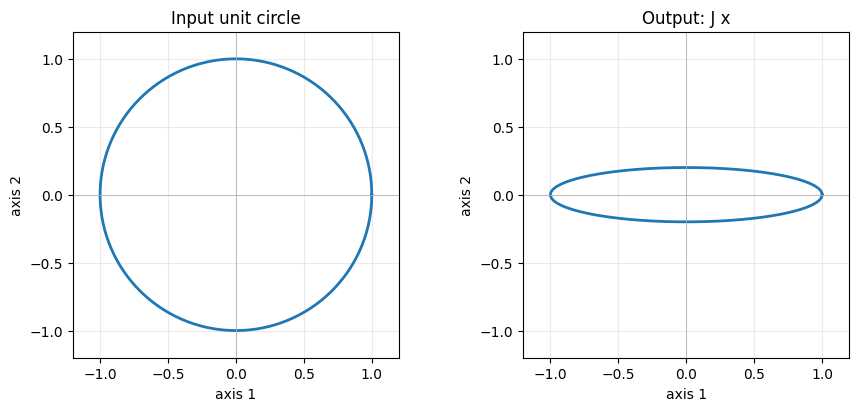

singular values = [1.  0.2]


In [5]:
eps_svd = 0.2  # 可修改，0 表示精确秩亏
J_visual = np.diag([1., eps_svd])
theta = np.linspace(0, 2 * np.pi, 400)
circle = np.vstack((np.cos(theta), np.sin(theta)))
mapped = J_visual @ circle
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, points, title in zip(axes, [circle, mapped], ['Input unit circle', 'Output: J x']):
    ax.plot(points[0], points[1], lw=2)
    ax.axhline(0, color='0.7', lw=.6); ax.axvline(0, color='0.7', lw=.6)
    ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), title=title, xlabel='axis 1', ylabel='axis 2')
    ax.set_aspect('equal'); ax.grid(alpha=.25)
plt.show()
print('singular values =', np.linalg.svd(J_visual, compute_uv=False))

## 3. 特征值、正定与半正定

对实对称 $H$，可写为 $H=Q\Lambda Q^\top$。若所有特征值都大于零，$H\succ0$；若都非负，$H\succeq0$，但允许零方向。一般矩阵的特征值和奇异值不是同一个东西：对称矩阵的奇异值是特征值的绝对值。

观察 $H_{\rm good}=\operatorname{diag}(2,1)$、$H_{\rm flat}=\operatorname{diag}(2,0)$、$H_{\rm indef}=\operatorname{diag}(2,-1)$ 的二次型，比较碗形、平坦方向和鞍形。

positive definite eigenvalues: [1. 2.] singular values: [2. 1.]
positive semidefinite eigenvalues: [0. 2.] singular values: [2. 0.]
indefinite eigenvalues: [-1.  2.] singular values: [2. 1.]


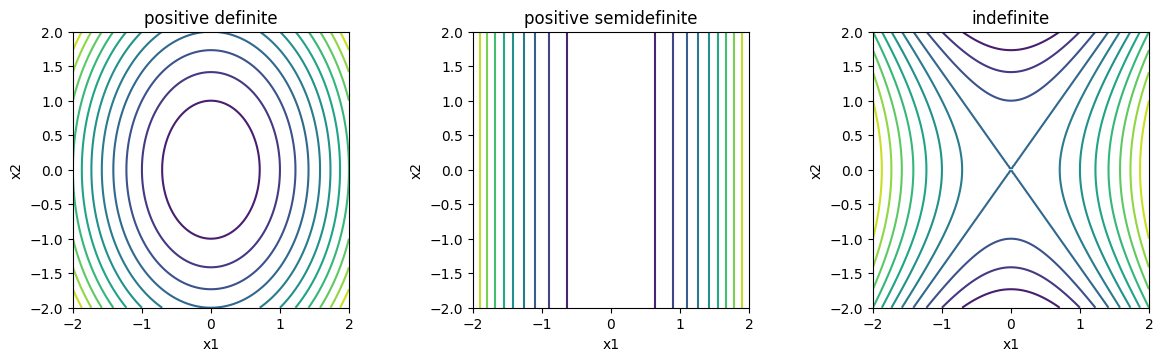

In [6]:
matrices = {'positive definite': np.diag([2., 1.]),
            'positive semidefinite': np.diag([2., 0.]),
            'indefinite': np.diag([2., -1.])}
for name, H in matrices.items():
    print(name, 'eigenvalues:', np.linalg.eigvalsh(H),
          'singular values:', np.linalg.svd(H, compute_uv=False))

grid = np.linspace(-2, 2, 120)
X, Y = np.meshgrid(grid, grid)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, (name, H) in zip(axes, matrices.items()):
    Z = 0.5 * (H[0, 0] * X**2 + 2 * H[0, 1] * X * Y + H[1, 1] * Y**2)
    ax.contour(X, Y, Z, levels=12, cmap='viridis')
    ax.set(title=name, xlabel='x1', ylabel='x2'); ax.set_aspect('equal')
plt.show()

如果 $W\succeq0$，则 $H=J^\top WJ$ 一定半正定，因为 $x^\top Hx=\|W^{1/2}Jx\|^2\ge0$。它正定当且仅当 $W^{1/2}J$ 满列秩。这里是 Gauss–Newton 矩阵；一般非线性目标的真实 Hessian 不一定半正定。

**练习**：下方的 $J$ 秩亏，检查 $J^\top J$ 的特征值。为什么不能说它正定？

In [7]:
H = A.T @ A
print('J^T J =\n', H)
print('eigenvalues =', np.linalg.eigvalsh(H))
assert np.allclose(np.linalg.eigvalsh(H), [0., 25.], atol=1e-12)

J^T J =
 [[ 5. 10.]
 [10. 20.]]
eigenvalues = [ 0. 25.]


## 4. 条件数：弱约束如何放大误差

对于满列秩矩阵，$\kappa_2(J)=\sigma_{\max}/\sigma_{\min}$。若 $J$ 满列秩，则 $\kappa_2(J^\top J)=\kappa_2(J)^2$；这描述的是正规方程矩阵的条件数。残差白化和变量单位会影响数值条件数；可逆缩放不改变精确秩。

下面只改变第二个观测 $10^{-4}$，比较状态估计变化。**练习**：将 `eps` 改为 $10^{-1}$、$10^{-3}$、$10^{-6}$，先手算第二个分量的变化。

In [8]:
eps = 1e-3  # 可修改；此格要求 eps != 0
J = np.diag([1., eps])
measurement_delta = np.array([0., 1e-4])
state_delta = np.linalg.solve(J, measurement_delta)
print('observation delta:', measurement_delta)
print('state delta:', state_delta)
print('cond(J):', np.linalg.cond(J))
print('cond(J.T @ J):', np.linalg.cond(J.T @ J))
assert np.isclose(np.linalg.cond(J.T @ J), np.linalg.cond(J)**2)

observation delta: [0.     0.0001]
state delta: [0.  0.1]
cond(J): 1000.0
cond(J.T @ J): 1000000.0


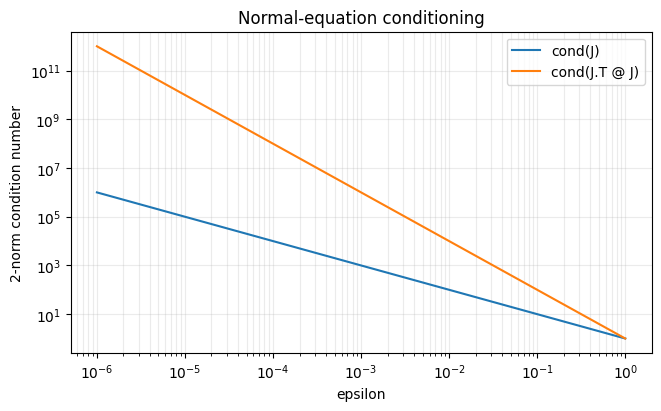

In [9]:
eps_values = np.logspace(-6, 0, 100)
condition_j = np.array([np.linalg.cond(np.diag([1., e])) for e in eps_values])
condition_h = condition_j**2
fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.loglog(eps_values, condition_j, label='cond(J)')
ax.loglog(eps_values, condition_h, label='cond(J.T @ J)')
ax.set(xlabel='epsilon', ylabel='2-norm condition number', title='Normal-equation conditioning')
ax.grid(True, which='both', alpha=.25); ax.legend(); plt.show()

## 5. QR：直接求最小二乘

对于 $m\ge n$ 且满列秩的 $A$，精简 QR 给出 $A=QR$、$Q^\top Q=I$，解 $Rx=Q^\top b$。最优残差与 $A$ 的列空间正交。基本无主元 QR 的三角回代依赖满列秩；秩亏时需要适合的秩揭示方法。

$$A=\begin{bmatrix}1&0\\1&1\\0&1\end{bmatrix},\quad b=\begin{bmatrix}1\\0\\0\end{bmatrix}.$$

**练习**：先预测 $A^\top(b-Ax)$ 应是什么，再运行并比较 `lstsq`。

In [10]:
A_qr = np.array([[1., 0.], [1., 1.], [0., 1.]])
b_qr = np.array([1., 0., 0.])
Q, R = np.linalg.qr(A_qr, mode='reduced')
x_qr = np.linalg.solve(R, Q.T @ b_qr)
x_lstsq = np.linalg.lstsq(A_qr, b_qr, rcond=None)[0]
residual = b_qr - A_qr @ x_qr
print('Q^T Q =\n', Q.T @ Q)
print('QR x =', x_qr, 'lstsq x =', x_lstsq)
print('residual =', residual, 'A^T residual =', A_qr.T @ residual)
assert np.allclose(x_qr, [2/3, -1/3])
assert np.allclose(x_qr, x_lstsq)
assert np.allclose(A_qr.T @ residual, 0, atol=1e-12)

Q^T Q =
 [[1. 0.]
 [0. 1.]]
QR x = [ 0.666667 -0.333333] lstsq x = [ 0.666667 -0.333333]
residual = [ 0.333333 -0.333333  0.333333] A^T residual = [0. 0.]


## 6. 规范自由度：只测相对位移的机器人

一维相对观测 $r=x_2-x_1-z$，则 $J=[-1\quad1]$。把两个位置同时加上 $c$，残差不变。这里零空间是整体平移，而不是传感器已经测到了全局原点。

**练习**：改变 `offset` 和两个位置，检查相对残差；再观察加一个固定 $x_1$ 的锚定行后，矩阵的秩如何变化。锚定是选择基准或加入假设，不等于获得新的真实传感器观测。

In [11]:
offset = 5.0
positions = np.array([2., 5.])
z_measurement = 3.
def relative_residual(p):
    return p[1] - p[0] - z_measurement

J_pose = np.array([[-1., 1.]])
H_pose = J_pose.T @ J_pose
J_anchored = np.vstack([J_pose, [1., 0.]])
print('before/after shift:', relative_residual(positions), relative_residual(positions + offset))
print('H eigenvalues:', np.linalg.eigvalsh(H_pose))
print('ranks: free =', np.linalg.matrix_rank(J_pose), 'anchored =', np.linalg.matrix_rank(J_anchored))
assert np.allclose(J_pose @ np.ones(2), 0)
assert np.allclose(np.linalg.eigvalsh(H_pose), [0., 2.])
assert np.linalg.matrix_rank(J_anchored) == 2

before/after shift: 0.0 0.0
H eigenvalues: [0. 2.]
ranks: free = 1 anchored = 2


## 7. Schur 补：先消去一个变量

$$
\begin{bmatrix} B&E\\E^\top&C\end{bmatrix}
\begin{bmatrix}\delta y\\\delta z\end{bmatrix}
=\begin{bmatrix}v\\w\end{bmatrix}.
$$

若 $C$ 可逆，先解 $S\delta y=v-EC^{-1}w$，再回代 $\delta z=C^{-1}(w-E^\top\delta y)$，其中 $S=B-EC^{-1}E^\top$。代码通过求解线性方程实现，不显式求逆。若 $C$ 奇异，不能直接套用该公式。

**手算**：$H=\left[\begin{smallmatrix}3&1\\1&2\end{smallmatrix}\right]$，右侧 $(5,4)^\top$。先算 $S$ 和两个分量，再用完整系统核对。

In [12]:
H = np.array([[3., 1.], [1., 2.]])
g = np.array([5., 4.])
B, E, C = H[:1, :1], H[:1, 1:], H[1:, 1:]
v, w = g[:1], g[1:]
S = B - E @ np.linalg.solve(C, E.T)
rhs = v - E @ np.linalg.solve(C, w)
y = np.linalg.solve(S, rhs)
z = np.linalg.solve(C, w - E.T @ y)
x_schur = np.r_[y, z]
x_direct = np.linalg.solve(H, g)
print('S =', S, 'reduced rhs =', rhs)
print('Schur:', x_schur, 'direct:', x_direct)
assert np.allclose(S, [[2.5]])
assert np.allclose(x_schur, [1.2, 1.4])
assert np.allclose(x_schur, x_direct)

S = [[2.5]] reduced rhs = [3.]
Schur: [1.2 1.4] direct: [1.2 1.4]


## 8. 稀疏填充：消去点后，相机为什么连起来？

以下玩具系统的变量顺序为 $(c_1,c_2,p_1,p_2)$。第一行提供锚定；$p_1$ 同时连接两个相机，$p_2$ 只连接第二个相机。它用于展示块结构，不是实际重投影模型。

**练习**：观察消元前 $B_{12}$ 和消元后 $S_{12}$。把 `use_anchor` 改为 `False`，观察 Schur 补的零方向。消元顺序、共视关系和实际非零值会影响填充。

camera block B =
 [[2. 0.]
 [0. 2.]]
reduced S =
 [[ 1.5 -0.5]
 [-0.5  0.5]]
eigenvalues(S) = [0.292893 1.707107]


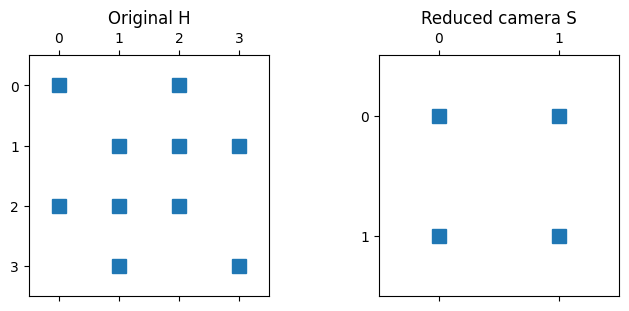

In [13]:
use_anchor = True  # 改为 False 观察 gauge
J_ba = np.array([[1., 0., 0., 0.],
                 [1., 0., 1., 0.],
                 [0., 1., 1., 0.],
                 [0., 1., 0., 1.]])
if not use_anchor:
    J_ba = J_ba[1:]
H_ba = J_ba.T @ J_ba
B, E, C = H_ba[:2, :2], H_ba[:2, 2:], H_ba[2:, 2:]
S_ba = B - E @ np.linalg.solve(C, E.T)
print('camera block B =\n', B)
print('reduced S =\n', S_ba)
print('eigenvalues(S) =', np.linalg.eigvalsh(S_ba))
if use_anchor:
    assert np.allclose(S_ba, [[1.5, -.5], [-.5, .5]])
else:
    assert np.allclose(S_ba @ np.ones(2), 0)

fig, axes = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)
for ax, matrix, title in zip(axes, [H_ba, S_ba], ['Original H', 'Reduced camera S']):
    ax.spy(matrix, markersize=10)
    ax.set_title(title)
plt.show()

## 9. Schur、边缘化和阻尼：三个不同操作

| 操作 | 目的 | 被消变量之后怎样处理 |
|---|---|---|
| 线性求解中的 Schur | 暂时降低当前线性系统维数 | 回代，下一轮原变量仍可重新线性化 |
| 固定窗口边缘化 | 将旧状态的局部信息压缩为先验 | 旧状态通常被丢弃，先验依赖形成时的线性化 |
| LM 阻尼 | 改变当前更新步的线性子问题 | 可与 Schur 一起用；阻尼不等于新的真实观测 |

对相关块可逆的线性高斯问题，消元和边缘化得到相同的保留变量二次信息形式。非线性固定窗口先验只是基于当时线性化点的局部近似。

## 10. 自测与下一步

先不看详细笔记，独立回答：

1. 对 $J=[-1\quad1]$，求秩、右零空间，以及 $J^\top J$ 的特征值；解释物理含义。
2. 满列秩 $J$ 的奇异值是 $10,1,10^{-3}$，求 $\kappa_2(J)$ 和 $\kappa_2(J^\top J)$。
3. 为什么 $J^\top J$ 一定半正定，却不一定能用普通 Cholesky 分解？
4. Schur 的点块 $C$ 可逆时，完整系统是否一定可逆？请解释。
5. 为什么很小的残差不能单独证明状态估计准确？

<details><summary>展开参考答案</summary>

1. 秩为 1；零空间为 $\operatorname{span}\{(1,1)^\top\}$；特征值为 $0,2$。整体平移不可由相对位移测出。
2. 分别为 $10^4$ 和 $10^8$。
3. 它可能秩亏并有零特征值；普通 Cholesky 所需的正定性不成立。
4. 不一定；保留变量的 Schur 补仍可能奇异，例如存在全局 gauge。
5. 病态或欠约束时，不同状态可以产生接近的残差；还要结合尺度、噪声与独立参考。

</details>

**后续练习**：将玩具矩阵替换成实际重投影 Jacobian；先核对坐标系、残差定义、扰动约定及解析/有限差分 Jacobian，再研究低视差与稀疏 BA。学习进度不因运行本 Notebook 自动标记完成。

### 参考资料

- [MIT OCW：SVD](https://ocw.mit.edu/courses/18-06sc-linear-algebra-fall-2011/pages/positive-definite-matrices-and-applications/singular-value-decomposition/)
- [LAPACK：QR Factorization](https://netlib.org/lapack/lug/node40.html)
- [MIT OCW：Numerical Methods](https://ocw.mit.edu/courses/18-335j-introduction-to-numerical-methods-spring-2019/pages/week-2/)
- [Ceres：非线性最小二乘与 Schur](https://ceres-solver.readthedocs.io/latest/nnls_solving.html)
- [Ceres：秩亏和规范自由度](https://ceres-solver.readthedocs.io/latest/nnls_covariance.html)
- [GTSAM：固定窗口边缘化示例](https://borglab.github.io/gtsam/fixedlagsmootherexample/)